<a href="https://colab.research.google.com/github/TY1Fan/CP4285-G1/blob/CFLF-model/music4all_onion_latent_factor_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Music4All-Onion: temporal collaborative filtering in Colab

A standalone, unexecuted notebook for downloading timestamped listening events, constructing calendar-year train/validation/test splits, training an implicit-feedback latent factor model, evaluating ranked song recommendations, and loading a saved model for inference.

**Before running:** upload this notebook at https://colab.research.google.com/ and choose a Python 3 CPU runtime. Edit the configuration cell, then run cells in order. No repository upload is required. The default experiment uses a deterministic **10% sample of whole users** to fit ordinary Colab resources. Set USER_FRACTION = 1.0 and EVAL_USER_LIMIT = None for the full experiment; the full data can require substantial disk space, RAM, and hours of processing. Sampling still requires reading the entire compressed download.

The official [Music4All-Onion v2 record](https://zenodo.org/records/15394646) provides userid_trackid_timestamp.tsv.bz2 (about 2.2 GB compressed). Download only this file: the all-time count file discards timestamps and would leak future activity into a temporal experiment. Audio and content features are unnecessary for collaborative filtering.

This notebook has no saved results. Its cells have not been run.


## Experimental protocol

- Default: **train 2014–2017; validation 2018; test 2019**. Other years are excluded and counted. Boundaries are explicit, globally shared January 1 cutoffs, not per-user/random splits or interaction-volume quantiles. Naive source timestamps are interpreted as UTC.
- Whole years preserve the calendar cycle; they do not make ordinary matrix factorization seasonal by themselves. The model is implicit ALS, optionally reranked with a month-of-year item-popularity lift learned from training events only. Validation selects the ALS settings and seasonal weight, including zero.
- User/item frequency thresholds, ID vocabularies, confidence weights, popularity baselines, and seasonal statistics use **training only**. No global k-core or future-activity filter is applied.
- Both held-out years use the **same frozen training snapshot**. There is no refit on validation and no online history update during either year. Test therefore measures a longer forecast horizon than validation. Validation labels select settings; test labels are evaluated only after the selected artifact is saved.
- The primary task is **song discovery**: rank every retained training-catalog song, excluding the user's retained training songs. Targets are distinct future songs per user/month that are in the training catalog and absent from that user's training history. A song can be relevant in several future months; repeat listening within a month is one relevance label.
- Report Precision@K, Recall@K, NDCG@K, HitRate@K, monthly results, catalog coverage, and cold-user/cold-song/previously-seen exclusions. Metrics are conditional on eligible warm discovery queries. These are not end-to-end metrics for all future events.
- By default, evaluation uses at most 2,000 users sampled from the training vocabulary **before reading validation labels**. The same saved cohort is used for validation and test. Set EVAL_USER_LIMIT = None for every training user.

The implementation follows the [implicit ALS API](https://benfred.github.io/implicit/api/models/cpu/als.html). Ranking uses all catalog items, not sampled negatives. The seasonal adjustment uses the known calendar month, never the held-out month's listening totals.


## 1. Install dependencies

Run this before importing NumPy/SciPy. These pins target Python 3.10–3.12. If Colab already imported a different NumPy version, restart the session after installation and resume at the imports/configuration cell. A GPU is optional and unused: this notebook explicitly uses CPU ALS.


In [1]:
%pip install -q "numpy==1.26.4" "pandas==2.2.3" "scipy==1.13.1" "implicit==0.7.2" "duckdb==1.4.1" "pyarrow==19.0.1" "matplotlib==3.9.4" "requests==2.32.5" "tqdm==4.67.1" "threadpoolctl==3.6.0"


## 2. Configuration

Use a new RUN_NAME whenever you change the data or training settings. A completed preprocessing stage can be reused after reconnecting by running imports/configuration, download verification, the DuckDB connection cell, and the later modeling cells; completed preprocessing is detected automatically.

Use Colab's local /content disk for processing. The final optional cell copies only the inference bundle to Google Drive. Raw data, split manifests, and detailed metrics remain local unless you copy them separately.


In [2]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "2"

import bz2
import gc
import hashlib
import importlib.metadata
import json
import re
import shutil
import time
from datetime import datetime, timezone
from functools import lru_cache
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import requests
from implicit.cpu.als import AlternatingLeastSquares
from requests.adapters import HTTPAdapter
from scipy import sparse
from threadpoolctl import threadpool_limits
from tqdm.auto import tqdm
from urllib3.util.retry import Retry

SEED = 42
ROOT = Path("/content/music4all_onion")
RUN_NAME = "yearly_2014_2017_val2018_test2019_users10pct_v1"

TRAIN_START_YEAR = 2014
TRAIN_END_YEAR = 2017
VAL_YEAR = 2018
TEST_YEAR = 2019
USER_FRACTION = 0.10             # 1.0 = full dataset; sample whole users, not rows
CHUNK_SIZE = 250_000
MIN_TRAIN_ITEMS_PER_USER = 5
MIN_TRAIN_USERS_PER_ITEM = 5
DUCKDB_MEMORY = "2GB"            # DuckDB can spill to local disk
CPU_THREADS = 2
KEEP_STAGING_FILES = False

K = 20
EVAL_USER_LIMIT = 2_000          # None = all retained training users
SCORE_BATCH_SIZE = 64           # reduce this to lower dense ranking RAM
SEASONAL_SMOOTHING = 100.0       # fixed prior mass; train-only monthly counts
SEASONAL_WEIGHTS = [0.0, 0.25, 0.5]
ALS_GRID = [
    {"factors": 64, "regularization": 0.1, "iterations": 20, "confidence_alpha": 20.0},
    {"factors": 128, "regularization": 0.1, "iterations": 20, "confidence_alpha": 20.0},
]

assert TRAIN_START_YEAR <= TRAIN_END_YEAR
assert VAL_YEAR == TRAIN_END_YEAR + 1 and TEST_YEAR == VAL_YEAR + 1
assert 0 < USER_FRACTION <= 1 and CHUNK_SIZE > 0
assert MIN_TRAIN_ITEMS_PER_USER >= 1 and MIN_TRAIN_USERS_PER_ITEM >= 1
assert K > 0 and SCORE_BATCH_SIZE > 0
assert EVAL_USER_LIMIT is None or EVAL_USER_LIMIT > 0
assert SEASONAL_SMOOTHING > 0 and ALS_GRID and SEASONAL_WEIGHTS
assert 0.0 in SEASONAL_WEIGHTS and all(w >= 0 for w in SEASONAL_WEIGHTS)
assert re.fullmatch(r"[A-Za-z0-9_-]+", RUN_NAME)

RAW_DIR = ROOT / "raw"
RUN_DIR = ROOT / "runs" / RUN_NAME
STAGING_DIR = RUN_DIR / "staging"
SPLIT_DIR = RUN_DIR / "manifests"
MODEL_DATA_DIR = RUN_DIR / "model_data"
REPORT_DIR = RUN_DIR / "reports"
BUNDLE_DIR = RUN_DIR / "bundle"
for directory in (RAW_DIR, RUN_DIR, MODEL_DATA_DIR, REPORT_DIR, BUNDLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "seed": SEED, "train_start_year": TRAIN_START_YEAR,
    "train_end_year": TRAIN_END_YEAR, "val_year": VAL_YEAR, "test_year": TEST_YEAR,
    "user_fraction": USER_FRACTION, "chunk_size": CHUNK_SIZE,
    "min_train_items_per_user": MIN_TRAIN_ITEMS_PER_USER,
    "min_train_users_per_item": MIN_TRAIN_USERS_PER_ITEM,
    "k": K, "eval_user_limit": EVAL_USER_LIMIT,
    "seasonal_smoothing": SEASONAL_SMOOTHING,
    "seasonal_weights": SEASONAL_WEIGHTS, "als_grid": ALS_GRID,
    "timestamp_interpretation": "UTC; source timestamps without timezone treated as UTC",
    "deduplication": "global exact (user_id, item_id, timestamp)",
    "protocol": "frozen train-only snapshot; monthly warm discovery; full-catalog ranking",
}
config_path = RUN_DIR / "config.json"
if config_path.exists() and json.loads(config_path.read_text()) != CONFIG:
    raise ValueError("This RUN_NAME has another configuration. Choose a new RUN_NAME.")
config_path.write_text(json.dumps(CONFIG, indent=2))
versions = {
    name: importlib.metadata.version(name)
    for name in ("numpy", "pandas", "scipy", "implicit", "duckdb", "pyarrow", "matplotlib")
}
(RUN_DIR / "environment.json").write_text(json.dumps(versions, indent=2))
np.random.seed(SEED)
print(json.dumps(CONFIG, indent=2))
print("Local free disk (GiB):", round(shutil.disk_usage(ROOT).free / 2**30, 1))


{
  "seed": 42,
  "train_start_year": 2014,
  "train_end_year": 2017,
  "val_year": 2018,
  "test_year": 2019,
  "user_fraction": 0.1,
  "chunk_size": 250000,
  "min_train_items_per_user": 5,
  "min_train_users_per_item": 5,
  "k": 20,
  "eval_user_limit": 2000,
  "seasonal_smoothing": 100.0,
  "seasonal_weights": [
    0.0,
    0.25,
    0.5
  ],
  "als_grid": [
    {
      "factors": 64,
      "regularization": 0.1,
      "iterations": 20,
      "confidence_alpha": 20.0
    },
    {
      "factors": 128,
      "regularization": 0.1,
      "iterations": 20,
      "confidence_alpha": 20.0
    }
  ],
  "timestamp_interpretation": "UTC; source timestamps without timezone treated as UTC",
  "deduplication": "global exact (user_id, item_id, timestamp)",
  "protocol": "frozen train-only snapshot; monthly warm discovery; full-catalog ranking"
}
Local free disk (GiB): 86.5


## 3. Download the official timestamped interaction file

The fixed release URL and MD5 below come from the [official v2 file listing](https://zenodo.org/records/15394646). The download is streamed to disk and verified before use; an existing verified file is reused. Interrupted downloads can be restarted by rerunning this cell (the partial download starts over). No archive is expanded into a huge TSV.


In [3]:
RECORD_ID = "15394646"
FILE_NAME = "userid_trackid_timestamp.tsv.bz2"
SOURCE_URL = f"https://zenodo.org/records/{RECORD_ID}/files/{FILE_NAME}?download=1"
EXPECTED_MD5 = "dfe82201036765f7463e6f3ce3d0f991"
RAW_PATH = RAW_DIR / FILE_NAME

def file_md5(path):
    digest = hashlib.md5()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

if RAW_PATH.exists():
    if file_md5(RAW_PATH) != EXPECTED_MD5:
        raise ValueError(f"Checksum mismatch for {RAW_PATH}. Move the bad file and rerun.")
    print("Reusing verified download:", RAW_PATH)
else:
    session = requests.Session()
    session.mount("https://", HTTPAdapter(max_retries=Retry(
        total=5, backoff_factor=2, status_forcelist=[429, 500, 502, 503, 504]
    )))
    partial = RAW_PATH.with_suffix(RAW_PATH.suffix + ".part")
    with session.get(SOURCE_URL, stream=True, timeout=(30, 180)) as response:
        response.raise_for_status()
        total = int(response.headers.get("content-length", 0)) or None
        with partial.open("wb") as handle, tqdm(
            total=total, unit="B", unit_scale=True, desc="Download"
        ) as progress:
            for block in response.iter_content(chunk_size=8 * 1024 * 1024):
                if block:
                    handle.write(block)
                    progress.update(len(block))
    if file_md5(partial) != EXPECTED_MD5:
        raise ValueError("Downloaded file failed MD5 verification; rerun this cell.")
    partial.replace(RAW_PATH)

(RUN_DIR / "source.json").write_text(json.dumps({
    "record_id": RECORD_ID, "file": FILE_NAME, "url": SOURCE_URL,
    "md5": EXPECTED_MD5, "bytes": RAW_PATH.stat().st_size,
}, indent=2))
print("Verified:", RAW_PATH)


Download:   0%|          | 0.00/2.21G [00:00<?, ?B/s]

Verified: /content/music4all_onion/raw/userid_trackid_timestamp.tsv.bz2


## 4. Stream, clean, deduplicate globally, and split by calendar year

pandas reads bounded chunks from bz2; cleaned chunks are staged as Parquet. DuckDB performs disk-backed global exact deduplication and writes event-level manifests partitioned by split. Every event in a calendar year belongs to the same split. Repeated listening at different timestamps is retained.

The deterministic user sample depends only on the user ID and SEED. It retains all in-window history of sampled users, including users that first appear in validation/test. Training frequency thresholds are applied later, using training only.

If this stage is interrupted, choose a new RUN_NAME to start cleanly. Completed preprocessing is reused; partial outputs are never silently appended.


In [4]:
def sql_string(value):
    return "'" + str(value).replace("'", "''") + "'"

# Re-running this cell closes the earlier connection in this Python session.
if "con" in globals():
    con.close()
con = duckdb.connect(str(RUN_DIR / "preprocessing.duckdb"))
con.execute(f"SET memory_limit = {sql_string(DUCKDB_MEMORY)}")
con.execute(f"SET threads = {int(CPU_THREADS)}")
con.execute(f"SET temp_directory = {sql_string(RUN_DIR / 'duckdb_tmp')}")
con.execute("SET preserve_insertion_order = false")

def split_glob(split):
    if split not in ("train", "val", "test"):
        raise ValueError("Expected train, val, or test.")
    return str(SPLIT_DIR / f"split={split}" / "*.parquet")

def split_scan(split):
    return f"read_parquet({sql_string(split_glob(split))}, hive_partitioning=true)"

@lru_cache(maxsize=500_000)
def retain_user(user_id):
    value = int.from_bytes(
        hashlib.sha256(f"{SEED}:{user_id}".encode("utf-8")).digest()[:8], "big"
    )
    return value < int(USER_FRACTION * 2**64)

def resolve_columns(columns):
    by_normalized = {
        re.sub(r"[^a-z0-9]", "", str(column).lower()): column
        for column in columns
    }
    result = []
    for label, names in (
        ("user", ("userid", "user", "listenerid", "uid")),
        ("song", ("trackid", "itemid", "songid", "musicid", "track", "song")),
        ("time", ("timestamp", "datetime", "playedat", "eventtime", "date")),
    ):
        found = next((by_normalized[name] for name in names if name in by_normalized), None)
        if found is None:
            raise ValueError(f"Cannot resolve {label} column from {list(columns)}.")
        result.append(found)
    return result


In [5]:
completion_path = RUN_DIR / "preprocessing_complete.json"
if completion_path.exists():
    cleaning_report = json.loads(completion_path.read_text())
    print("Reusing completed split manifests.")
else:
    if ((STAGING_DIR.exists() and any(STAGING_DIR.iterdir()))
            or (SPLIT_DIR.exists() and any(SPLIT_DIR.iterdir()))):
        raise FileExistsError("Partial preprocessing exists. Use a new RUN_NAME.")
    STAGING_DIR.mkdir(parents=True, exist_ok=True)
    SPLIT_DIR.mkdir(parents=True, exist_ok=True)
    header = pd.read_csv(RAW_PATH, sep="\t", compression="bz2", nrows=0).columns
    user_col, item_col, time_col = resolve_columns(header)
    print("Source columns:", user_col, item_col, time_col)
    cleaning_report = {
        "raw_rows": 0, "invalid_rows": 0, "valid_rows_outside_year_window": 0,
        "in_window_rows_before_sampling": 0, "sampled_rows_before_deduplication": 0,
        "rows_after_chunk_deduplication": 0,
    }
    chunks_written = 0
    reader = pd.read_csv(
        RAW_PATH, sep="\t", compression="bz2",
        usecols=[user_col, item_col, time_col], dtype="string",
        chunksize=CHUNK_SIZE, keep_default_na=False,
    )
    for chunk in tqdm(reader, desc="Stream compressed events", unit="chunks"):
        cleaning_report["raw_rows"] += len(chunk)
        frame = chunk.rename(columns={
            user_col: "user_id", item_col: "item_id", time_col: "timestamp"
        })[["user_id", "item_id", "timestamp"]].copy()
        frame["user_id"] = frame["user_id"].str.strip()
        frame["item_id"] = frame["item_id"].str.strip()
        frame["timestamp"] = pd.to_datetime(
            frame["timestamp"].str.strip(), format="%Y-%m-%d %H:%M:%S",
            utc=True, errors="coerce",
        )
        valid = (
            frame["timestamp"].notna()
            & frame["user_id"].notna() & frame["user_id"].ne("")
            & frame["item_id"].notna() & frame["item_id"].ne("")
        )
        cleaning_report["invalid_rows"] += int((~valid).sum())
        frame = frame.loc[valid].copy()
        frame["year"] = frame["timestamp"].dt.year.astype("int16")
        frame["month"] = frame["timestamp"].dt.month.astype("int8")
        in_window = frame["year"].between(TRAIN_START_YEAR, TEST_YEAR)
        cleaning_report["valid_rows_outside_year_window"] += int((~in_window).sum())
        frame = frame.loc[in_window].copy()
        cleaning_report["in_window_rows_before_sampling"] += len(frame)
        if USER_FRACTION < 1.0 and not frame.empty:
            sampled = {u: retain_user(u) for u in frame["user_id"].unique()}
            frame = frame.loc[frame["user_id"].map(sampled)].copy()
        cleaning_report["sampled_rows_before_deduplication"] += len(frame)
        frame = frame.drop_duplicates(["user_id", "item_id", "timestamp"])
        cleaning_report["rows_after_chunk_deduplication"] += len(frame)
        if not frame.empty:
            frame.to_parquet(
                STAGING_DIR / f"chunk_{chunks_written:06d}.parquet",
                index=False, compression="zstd",
            )
            chunks_written += 1
    if chunks_written == 0:
        raise ValueError("No events remain. Check year boundaries and source format.")

    # One DISTINCT across every staged chunk also removes cross-chunk duplicates.
    con.execute(f"""
        COPY (
            SELECT DISTINCT user_id, item_id, timestamp, year, month,
                CASE
                    WHEN year <= {TRAIN_END_YEAR} THEN 'train'
                    WHEN year = {VAL_YEAR} THEN 'val'
                    ELSE 'test'
                END AS split
            FROM read_parquet({sql_string(STAGING_DIR / '*.parquet')})
        ) TO {sql_string(SPLIT_DIR)}
        (FORMAT PARQUET, PARTITION_BY (split), COMPRESSION ZSTD, ROW_GROUP_SIZE 100000)
    """)
    for split in ("train", "val", "test"):
        if not list((SPLIT_DIR / f"split={split}").glob("*.parquet")):
            raise ValueError(f"Empty {split} split. Use a new RUN_NAME with other years.")
    total_clean = con.execute(f"""
        SELECT count(*) FROM read_parquet(
            {sql_string(SPLIT_DIR / 'split=*' / '*.parquet')},
            hive_partitioning=true
        )
    """).fetchone()[0]
    cleaning_report["deduplicated_events"] = int(total_clean)
    cleaning_report["exact_duplicates_removed"] = (
        cleaning_report["sampled_rows_before_deduplication"] - int(total_clean)
    )
    # Checkpoint only after all three manifests have been written successfully.
    completion_path.write_text(json.dumps(cleaning_report, indent=2))
    if not KEEP_STAGING_FILES:
        # Remove only generated staging chunks for this run.
        for path in STAGING_DIR.glob("chunk_*.parquet"):
            path.unlink()
        STAGING_DIR.rmdir()

display(pd.Series(cleaning_report, name="rows").to_frame())


Source columns: user_id track_id timestamp


Stream compressed events: 0chunks [00:00, ?chunks/s]

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,rows
raw_rows,252984396
invalid_rows,0
valid_rows_outside_year_window,125060811
in_window_rows_before_sampling,127923585
sampled_rows_before_deduplication,13362394
rows_after_chunk_deduplication,13362376
deduplicated_events,13362376
exact_duplicates_removed,18


## 5. Audit chronology and calendar coverage

These checks execute when you run Colab. They check actual timestamp ranges, nonempty splits, year separation, exact duplicate removal, and the presence of each calendar month. Counts and charts describe split construction; they do not fit preprocessing parameters or select the model.

Missing months can indicate partial observation coverage. A file having events in every month does not prove every user has a complete year of history.


,events,users,songs,first_event,last_event,first_year,last_year
split,,,,,,,
train,9769411,5933,48037,2014-01-01 00:00:06+00:00,2017-12-31 23:59:47+00:00,2014,2017
val,1798322,2178,49625,2018-01-01 00:00:06+00:00,2018-12-31 23:59:48+00:00,2018,2018
test,1794643,1771,51078,2019-01-01 00:00:02+00:00,2019-12-31 23:59:51+00:00,2019,2019


test calendar months present: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
train calendar months present: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
val calendar months present: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


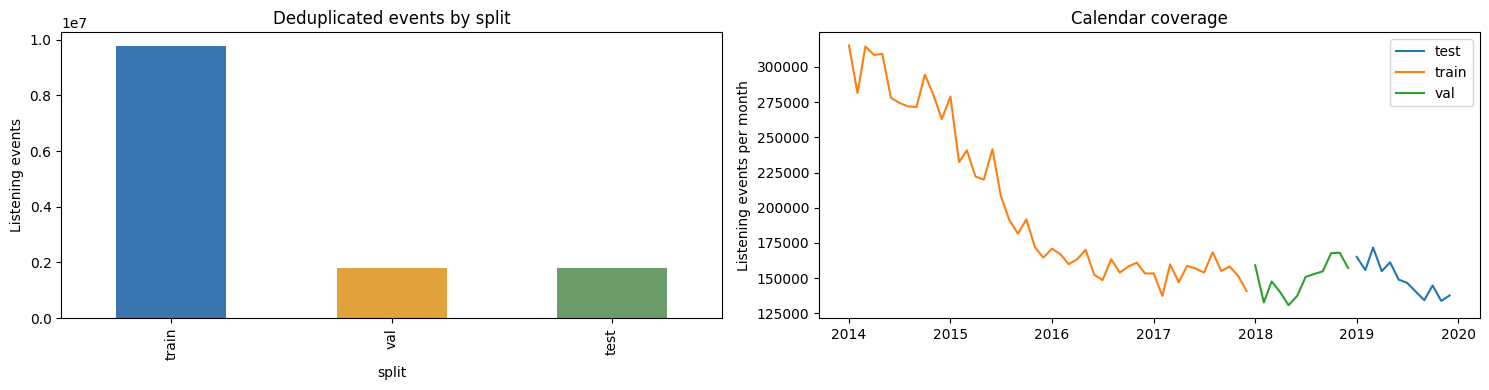

split,test,train,val
month,,,
1,165036,918516,159079
2,155641,817908,132627
3,171673,874972,147618
4,154846,841097,139921
5,161167,857921,130675
6,148874,828672,137289
7,146635,785404,150722
8,140446,794843,152874
9,134257,761812,154748


In [6]:
split_rows = []
calendar_rows = []
manifest_inventory = {}
for split in ("train", "val", "test"):
    scan = split_scan(split)
    row = con.execute(f"""
        SELECT count(*) AS events, count(DISTINCT user_id) AS users,
               count(DISTINCT item_id) AS songs,
               min(timestamp) AS first_event, max(timestamp) AS last_event,
               min(year) AS first_year, max(year) AS last_year
        FROM {scan}
    """).df().iloc[0].to_dict()
    row["split"] = split
    split_rows.append(row)
    monthly = con.execute(f"""
        SELECT split, year, month, count(*) AS events
        FROM {scan} GROUP BY split, year, month ORDER BY year, month
    """).df()
    calendar_rows.append(monthly)
    manifest_inventory[split] = {
        "glob": split_glob(split), "events": int(row["events"]),
        "natural_event_key": ["user_id", "item_id", "timestamp"],
        "files": [
            {"path": str(p.relative_to(RUN_DIR)), "bytes": p.stat().st_size}
            for p in sorted((SPLIT_DIR / f"split={split}").glob("*.parquet"))
        ],
    }

summary = pd.DataFrame(split_rows).set_index("split").loc[["train", "val", "test"]]
assert (summary["events"] > 0).all()
assert summary.loc["train", "last_event"] < summary.loc["val", "first_event"]
assert summary.loc["val", "last_event"] < summary.loc["test", "first_event"]
assert summary.loc["train", "first_year"] >= TRAIN_START_YEAR
assert summary.loc["train", "last_year"] <= TRAIN_END_YEAR
assert summary.loc["val", "first_year"] == summary.loc["val", "last_year"] == VAL_YEAR
assert summary.loc["test", "first_year"] == summary.loc["test", "last_year"] == TEST_YEAR
assert int(summary["events"].sum()) == cleaning_report["deduplicated_events"]
summary.to_csv(REPORT_DIR / "split_summary.csv")
(RUN_DIR / "SPLIT_METADATA.json").write_text(json.dumps({
    "configuration": CONFIG, "source": json.loads((RUN_DIR / "source.json").read_text()),
    "boundaries": {
        "train_start_inclusive": f"{TRAIN_START_YEAR}-01-01T00:00:00Z",
        "train_end_exclusive": f"{VAL_YEAR}-01-01T00:00:00Z",
        "val_end_exclusive": f"{TEST_YEAR}-01-01T00:00:00Z",
        "test_end_exclusive": f"{TEST_YEAR + 1}-01-01T00:00:00Z",
    },
    "manifests": manifest_inventory, "cleaning": cleaning_report,
}, indent=2))
display(summary)

calendar = pd.concat(calendar_rows, ignore_index=True)
calendar["period"] = pd.to_datetime(dict(
    year=calendar["year"], month=calendar["month"], day=1
), utc=True)
calendar.to_csv(REPORT_DIR / "calendar_counts.csv", index=False)
for split, group in calendar.groupby("split"):
    present = sorted(group["month"].unique().tolist())
    print(split, "calendar months present:", present)
    if len(present) < 12:
        print("Partial calendar coverage: interpret seasonal comparisons carefully.")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
summary["events"].plot.bar(ax=axes[0], color=["#3976af", "#e2a23b", "#6b9b68"])
axes[0].set_title("Deduplicated events by split")
axes[0].set_ylabel("Listening events")
for split, group in calendar.groupby("split"):
    axes[1].plot(group["period"], group["events"], label=split)
axes[1].set_title("Calendar coverage")
axes[1].set_ylabel("Listening events per month")
axes[1].legend()
fig.tight_layout()
fig.savefig(REPORT_DIR / "split_audit.png", dpi=150)
plt.show()

month_table = calendar.groupby(["split", "month"])["events"].sum().unstack("split")
display(month_table.reindex(range(1, 13)).fillna(0).astype("int64"))


## 6. Fit the training vocabulary and sparse user-song matrix

Frequency filtering uses training events only. First retain users with at least MIN_TRAIN_ITEMS_PER_USER distinct training songs; then retain songs heard by at least MIN_TRAIN_USERS_PER_ITEM of those users. Finally construct mappings from the remaining training pairs. This is a single filtering pass, not an iterative k-core; final user degrees can fall below the initial user threshold.

The raw training play count r_ui becomes confidence c_ui = 1 + alpha * log(1 + r_ui). Observed preferences are 1; missing pairs have preference 0 and confidence 1. ALS minimizes the confidence-weighted squared preference error plus L2 regularization. Missing plays are weak evidence, not explicit dislikes. The matrix orientation passed to implicit is **users × songs**.

Only one sparse matrix is materialized from disk, in numeric batches. No full event DataFrame or dense user-song training matrix is constructed. ALS also allocates a sparse transpose and factor arrays during training.


In [7]:
train_scan = split_scan("train")
con.execute(f"""
    CREATE OR REPLACE TABLE raw_train_pairs AS
    SELECT user_id, item_id, count(*)::BIGINT AS plays
    FROM {train_scan} GROUP BY user_id, item_id
""")
con.execute(f"""
    CREATE OR REPLACE TABLE retained_users AS
    SELECT user_id FROM raw_train_pairs GROUP BY user_id
    HAVING count(*) >= {MIN_TRAIN_ITEMS_PER_USER}
""")
con.execute(f"""
    CREATE OR REPLACE TABLE retained_items AS
    SELECT p.item_id FROM raw_train_pairs p
    JOIN retained_users u USING (user_id)
    GROUP BY p.item_id HAVING count(*) >= {MIN_TRAIN_USERS_PER_ITEM}
""")
con.execute("""
    CREATE OR REPLACE TABLE filtered_train_pairs AS
    SELECT p.* FROM raw_train_pairs p
    JOIN retained_users u USING (user_id)
    JOIN retained_items i USING (item_id)
""")
n_pairs = int(con.execute("SELECT count(*) FROM filtered_train_pairs").fetchone()[0])
if n_pairs == 0:
    raise ValueError("No training pairs survive. Lower training-only thresholds or sample more users.")
con.execute("""
    CREATE OR REPLACE TABLE user_map AS
    SELECT user_id, (row_number() OVER (ORDER BY user_id) - 1)::INTEGER AS user_index
    FROM (SELECT DISTINCT user_id FROM filtered_train_pairs)
""")
con.execute("""
    CREATE OR REPLACE TABLE item_map AS
    SELECT item_id, (row_number() OVER (ORDER BY item_id) - 1)::INTEGER AS item_index
    FROM (SELECT DISTINCT item_id FROM filtered_train_pairs)
""")
con.execute("""
    CREATE OR REPLACE TABLE train_pairs AS
    SELECT u.user_index, i.item_index, p.plays
    FROM filtered_train_pairs p
    JOIN user_map u USING (user_id) JOIN item_map i USING (item_id)
""")

def copy_query_to_parquet(query, path):
    path = Path(path)
    # These are generated outputs within this configured run directory.
    if path.exists():
        path.unlink()
    con.execute(f"COPY ({query}) TO {sql_string(path)} (FORMAT PARQUET, COMPRESSION ZSTD)")

copy_query_to_parquet("SELECT * FROM user_map ORDER BY user_index", MODEL_DATA_DIR / "users.parquet")
copy_query_to_parquet("SELECT * FROM item_map ORDER BY item_index", MODEL_DATA_DIR / "items.parquet")
# CSR construction below relies on this file's explicit row ordering.
con.execute("SET preserve_insertion_order = true")
try:
    copy_query_to_parquet(
        "SELECT * FROM train_pairs ORDER BY user_index, item_index",
        MODEL_DATA_DIR / "train_pairs.parquet",
    )
finally:
    con.execute("SET preserve_insertion_order = false")
users_df = pd.read_parquet(MODEL_DATA_DIR / "users.parquet")
items_df = pd.read_parquet(MODEL_DATA_DIR / "items.parquet")
user_ids = users_df["user_id"].astype(str).to_numpy()
item_ids = items_df["item_id"].astype(str).to_numpy()
n_users, n_items = len(user_ids), len(item_ids)
assert 1 <= K <= n_items, "K must not exceed the retained training catalog size."
assert max(n_users, n_items, n_pairs) < np.iinfo(np.int32).max

# These large string-keyed intermediate tables are no longer needed.
for table in ("raw_train_pairs", "retained_users", "retained_items", "filtered_train_pairs"):
    con.execute(f"DROP TABLE {table}")

def load_train_csr(path, n_users, n_items):
    parquet = pq.ParquetFile(path)
    nnz = parquet.metadata.num_rows
    indices = np.empty(nnz, dtype=np.int32)
    data = np.empty(nnz, dtype=np.float32)
    row_counts = np.zeros(n_users, dtype=np.int64)
    offset = 0
    previous_last_user = -1
    for batch in parquet.iter_batches(batch_size=250_000):
        frame = batch.to_pandas()
        rows = frame["user_index"].to_numpy(dtype=np.int32)
        cols = frame["item_index"].to_numpy(dtype=np.int32)
        values = frame["plays"].to_numpy(dtype=np.float32)
        assert len(rows) and rows[0] >= previous_last_user
        assert np.all(rows[1:] >= rows[:-1]), "Expected ordered train pairs."
        previous_last_user = int(rows[-1])
        end = offset + len(rows)
        indices[offset:end] = cols
        data[offset:end] = values
        row_counts += np.bincount(rows, minlength=n_users)
        offset = end
    indptr = np.empty(n_users + 1, dtype=np.int32)
    indptr[0] = 0
    indptr[1:] = np.cumsum(row_counts)
    matrix = sparse.csr_matrix((data, indices, indptr), shape=(n_users, n_items))
    matrix.sort_indices()
    assert matrix.nnz == nnz and (matrix.data > 0).all()
    assert (np.diff(matrix.indptr) > 0).all()
    return matrix

train_counts = load_train_csr(MODEL_DATA_DIR / "train_pairs.parquet", n_users, n_items)
sparse.save_npz(MODEL_DATA_DIR / "train_counts.npz", train_counts)
print({
    "training_users": n_users, "training_catalog_songs": n_items,
    "nonzero_training_pairs": train_counts.nnz,
    "CSR_MiB": round(
        (train_counts.data.nbytes + train_counts.indices.nbytes + train_counts.indptr.nbytes) / 2**20, 1
    ),
    "density": train_counts.nnz / (n_users * n_items),
})


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

{'training_users': 5463, 'training_catalog_songs': 41834, 'nonzero_training_pairs': 2116066, 'CSR_MiB': 16.2, 'density': 0.009259096632120899}


## 7. Train-only popularity and seasonal features

Global popularity counts distinct training listeners per song. Month-of-year popularity counts distinct retained training listeners per song/month, pooling the training years. A smoothed month-specific distribution backs off to the pooled prior. The seasonal feature is its clipped log lift relative to that prior, standardized within each month.

ALS scores are standardized over the training catalog per user before adding the seasonal feature. Weight zero preserves pure ALS ranking. All distributions below are calculated before accessing validation targets.


In [8]:
popular = con.execute("""
    SELECT item_index, count(*) AS listeners
    FROM train_pairs GROUP BY item_index
""").df()
global_popularity = np.zeros(n_items, dtype=np.float32)
global_popularity[popular["item_index"].to_numpy()] = popular["listeners"].to_numpy()

month_counts_df = con.execute(f"""
    SELECT e.month, i.item_index, count(DISTINCT e.user_id) AS listeners
    FROM {train_scan} e
    JOIN user_map u USING (user_id) JOIN item_map i USING (item_id)
    GROUP BY e.month, i.item_index
""").df()
month_counts = np.zeros((12, n_items), dtype=np.float64)
month_counts[
    month_counts_df["month"].to_numpy(dtype=int) - 1,
    month_counts_df["item_index"].to_numpy(dtype=int),
] = month_counts_df["listeners"].to_numpy()

pooled = month_counts.sum(axis=0)
prior = (pooled + 1.0) / (pooled.sum() + n_items)
seasonal_popularity = (
    month_counts + SEASONAL_SMOOTHING * prior[None, :]
) / (month_counts.sum(axis=1, keepdims=True) + SEASONAL_SMOOTHING)
lift = np.clip(np.log(seasonal_popularity / prior[None, :]), -3.0, 3.0)
seasonal_features = (
    (lift - lift.mean(axis=1, keepdims=True))
    / np.maximum(lift.std(axis=1, keepdims=True), 1e-6)
).astype(np.float32)
seasonal_popularity = seasonal_popularity.astype(np.float32)
np.savez_compressed(
    MODEL_DATA_DIR / "priors.npz",
    global_popularity=global_popularity,
    seasonal_popularity=seasonal_popularity,
    seasonal_features=seasonal_features,
)
del month_counts, month_counts_df, pooled, prior, lift
gc.collect()

# Select evaluation users using training IDs only, then persist the exact cohort.
rng = np.random.default_rng(SEED)
if EVAL_USER_LIMIT is None or EVAL_USER_LIMIT >= n_users:
    eval_users = np.arange(n_users, dtype=np.int32)
else:
    eval_users = np.sort(rng.choice(n_users, EVAL_USER_LIMIT, replace=False)).astype(np.int32)
np.save(MODEL_DATA_DIR / "eval_user_indices.npy", eval_users)
con.register("eval_user_ids", pd.DataFrame({"user_index": eval_users}))
print(f"Evaluation cohort: {len(eval_users):,} of {n_users:,} retained training users.")


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Evaluation cohort: 2,000 of 5,463 retained training users.


## 8. Evaluation pipeline

Ground truth is a set of unique songs for each eligible user/month. A user with no eligible positive songs in a month does not form a ranking query; counts of those exclusions are reported. Unknown users and songs cannot be scored by a pure collaborative model and are explicitly reported. Unknown means absent from the retained training vocabulary: it includes IDs removed by training-only frequency thresholds as well as genuinely new future IDs.

At each query, every retained training song is a candidate except that user's retained training songs. User history remains frozen even in later months and in the test year. Therefore a validation-year discovery can still be a test-year target; it is not added to the user's history.

Precision = hits/K; Recall = hits/number of relevant songs; HitRate = any hit; NDCG uses binary relevance and an ideal list of min(K, number of relevant songs). Aggregate metrics average active user/month queries equally. A second table averages each user's monthly metrics first and then averages users. Catalog coverage is the fraction of training songs appearing in any top-K list.


In [9]:
def target_queries(split):
    """Read held-out labels only when this function is explicitly called."""
    scan = split_scan(split)
    # Classification is disjoint: cold user, then cold item, then warm seen/novel.
    joined = f"""
        WITH future AS (
            SELECT DISTINCT month, user_id, item_id FROM {scan}
        )
        SELECT f.month, f.user_id, f.item_id, u.user_index, i.item_index,
               p.user_index IS NOT NULL AS seen_in_train,
               c.user_index IS NOT NULL AS in_eval_cohort
        FROM future f
        LEFT JOIN user_map u USING (user_id)
        LEFT JOIN item_map i USING (item_id)
        LEFT JOIN train_pairs p
            ON p.user_index = u.user_index AND p.item_index = i.item_index
        LEFT JOIN eval_user_ids c ON c.user_index = u.user_index
    """
    coverage = con.execute(f"""
        WITH joined AS ({joined})
        SELECT month,
            count(*) AS all_user_month_song_labels,
            count(DISTINCT user_id) AS all_active_users,
            count(*) FILTER (WHERE user_index IS NULL) AS cold_user_labels,
            count(*) FILTER (
                WHERE user_index IS NOT NULL AND item_index IS NULL
            ) AS cold_item_labels_among_known_users,
            count(*) FILTER (
                WHERE user_index IS NOT NULL AND item_index IS NOT NULL AND seen_in_train
            ) AS warm_previously_seen_labels,
            count(*) FILTER (
                WHERE user_index IS NOT NULL AND item_index IS NOT NULL AND NOT seen_in_train
            ) AS warm_discovery_labels,
            count(*) FILTER (
                WHERE user_index IS NOT NULL AND item_index IS NOT NULL
                    AND NOT seen_in_train AND in_eval_cohort
            ) AS evaluated_discovery_labels,
            count(DISTINCT user_id) FILTER (
                WHERE user_index IS NOT NULL AND item_index IS NOT NULL
                    AND NOT seen_in_train AND in_eval_cohort
            ) AS evaluated_active_users
        FROM joined GROUP BY month ORDER BY month
    """).df()
    classified_columns = [
        "cold_user_labels", "cold_item_labels_among_known_users",
        "warm_previously_seen_labels", "warm_discovery_labels",
    ]
    assert (
        coverage[classified_columns].sum(axis=1)
        == coverage["all_user_month_song_labels"]
    ).all()
    # Only the fixed evaluation cohort's eligible labels are loaded into Python.
    frame = con.execute(f"""
        WITH joined AS ({joined})
        SELECT month, user_index, list(item_index ORDER BY item_index) AS relevant_items
        FROM joined
        WHERE user_index IS NOT NULL AND item_index IS NOT NULL
            AND NOT seen_in_train AND in_eval_cohort
        GROUP BY month, user_index ORDER BY month, user_index
    """).df()
    if frame.empty:
        raise ValueError(f"No eligible {split} queries; inspect coverage, sample size, and thresholds.")
    coverage["eligible_label_fraction"] = (
        coverage["warm_discovery_labels"] / coverage["all_user_month_song_labels"]
    )
    coverage.to_csv(REPORT_DIR / f"{split}_target_coverage.csv", index=False)
    return frame, coverage

def standardized_rows(values):
    return (
        (values - values.mean(axis=1, keepdims=True))
        / np.maximum(values.std(axis=1, keepdims=True), 1e-6)
    )

def ranking_scores(model, user_indices, month, mode="als", seasonal_weight=0.0):
    if mode == "popularity":
        return np.broadcast_to(
            global_popularity, (len(user_indices), n_items)
        ).copy()
    if mode == "seasonal_popularity":
        return np.broadcast_to(
            seasonal_popularity[month - 1], (len(user_indices), n_items)
        ).copy()
    if mode != "als" or model is None:
        raise ValueError("Expected ALS model or supported popularity baseline.")
    scores = model.user_factors[user_indices] @ model.item_factors.T
    if seasonal_weight:
        scores = standardized_rows(scores)
        scores += seasonal_weight * seasonal_features[month - 1]
    return scores

def recommend_batch(model, user_indices, month, k=K, mode="als", seasonal_weight=0.0):
    user_indices = np.asarray(user_indices, dtype=np.int32)
    scores = ranking_scores(model, user_indices, month, mode, seasonal_weight)
    if not np.isfinite(scores).all():
        raise ValueError("Non-finite ranking scores.")
    for local, user in enumerate(user_indices):
        start, stop = train_counts.indptr[user:user + 2]
        scores[local, train_counts.indices[start:stop]] = -np.inf
    take = min(int(k), n_items)
    candidates = np.argpartition(scores, n_items - take, axis=1)[:, -take:]
    values = np.take_along_axis(scores, candidates, axis=1)
    # Break ties among selected items by catalog index.
    order = np.lexsort((candidates, -values), axis=1)
    candidates = np.take_along_axis(candidates, order, axis=1)
    values = np.take_along_axis(values, order, axis=1)
    candidates[~np.isfinite(values)] = -1  # fewer than K available songs
    return candidates, values

METRIC_COLUMNS = [f"precision@{K}", f"recall@{K}", f"ndcg@{K}", f"hitrate@{K}"]

def evaluate(model, queries, label, mode="als", seasonal_weight=0.0, save_details=False):
    records = []
    recommended_catalog = set()
    discount = 1.0 / np.log2(np.arange(2, K + 2))
    for month, group in queries.groupby("month", sort=True):
        user_array = group["user_index"].to_numpy(dtype=np.int32)
        relevant_arrays = group["relevant_items"].tolist()
        for offset in range(0, len(group), SCORE_BATCH_SIZE):
            batch_users = user_array[offset:offset + SCORE_BATCH_SIZE]
            recommended, _ = recommend_batch(
                model, batch_users, int(month), K, mode, seasonal_weight
            )
            targets = relevant_arrays[offset:offset + SCORE_BATCH_SIZE]
            for user, pred, target in zip(batch_users, recommended, targets):
                target = np.asarray(target, dtype=np.int32)
                assert len(target) > 0 and len(np.unique(target)) == len(target)
                hits = np.isin(pred, target) & (pred >= 0)
                hit_count = int(hits.sum())
                ideal_dcg = discount[:min(len(target), K)].sum()
                records.append({
                    "month": int(month), "user_index": int(user),
                    "relevant_songs": len(target), "returned_songs": int((pred >= 0).sum()),
                    f"precision@{K}": hit_count / K,
                    f"recall@{K}": hit_count / len(target),
                    f"ndcg@{K}": float((hits * discount).sum() / ideal_dcg),
                    f"hitrate@{K}": float(hit_count > 0),
                })
                recommended_catalog.update(pred[pred >= 0].tolist())
    detail = pd.DataFrame(records)
    monthly = detail.groupby("month")[METRIC_COLUMNS].mean()
    monthly["queries"] = detail.groupby("month").size()
    overall = {
        "label": label, **detail[METRIC_COLUMNS].mean().to_dict(),
        "queries": len(detail), "users": int(detail["user_index"].nunique()),
        "catalog_coverage": len(recommended_catalog) / n_items,
    }
    user_macro = detail.groupby("user_index")[METRIC_COLUMNS].mean().mean()
    overall.update({f"user_macro_{key}": float(value) for key, value in user_macro.items()})
    assert ((detail[METRIC_COLUMNS] >= 0) & (detail[METRIC_COLUMNS] <= 1 + 1e-8)).all().all()
    if save_details:
        detail.to_parquet(REPORT_DIR / f"{label}_query_metrics.parquet", index=False)
        monthly.to_csv(REPORT_DIR / f"{label}_monthly_metrics.csv")
        (REPORT_DIR / f"{label}_metrics.json").write_text(json.dumps(overall, indent=2))
    return overall, monthly


## 9. Training and validation-based model selection

Train each ALS configuration on training events only. Evaluate each seasonal weight on the same validation queries and choose the highest mean user/month NDCG@K. Ties keep the first candidate, so the zero seasonal weight is preferred when tied. The test targets are not loaded in this stage.

The training callback records iteration timing. Computing the full ALS training objective is disabled to avoid an extra pass each iteration; ranking metrics, rather than training loss, select the model. The two configurations are an editable starter search, not a claim of optimal hyperparameters.


In [10]:
validation_queries, validation_coverage = target_queries("val")
display(validation_coverage)

def make_confidence(counts, alpha):
    confidence = counts.copy()
    confidence.data = (1.0 + float(alpha) * np.log1p(confidence.data)).astype(np.float32)
    return confidence

def train_als(parameters, experiment):
    confidence = make_confidence(train_counts, parameters["confidence_alpha"])
    model = AlternatingLeastSquares(
        factors=int(parameters["factors"]),
        regularization=float(parameters["regularization"]),
        iterations=int(parameters["iterations"]),
        alpha=1.0,                 # confidence_alpha was applied exactly once above
        dtype=np.float32, num_threads=CPU_THREADS,
        random_state=SEED, calculate_training_loss=False,
    )
    timing = []
    def callback(iteration, elapsed, loss):
        timing.append({"iteration": int(iteration) + 1, "seconds": float(elapsed)})
    with threadpool_limits(limits=1, user_api="blas"):
        model.fit(confidence, callback=callback, show_progress=True)
    assert model.user_factors.shape == (n_users, parameters["factors"])
    assert model.item_factors.shape == (n_items, parameters["factors"])
    assert np.isfinite(model.user_factors).all() and np.isfinite(model.item_factors).all()
    pd.DataFrame(timing).to_csv(REPORT_DIR / f"{experiment}_training_timing.csv", index=False)
    del confidence
    gc.collect()
    return model

selection_path = BUNDLE_DIR / "selection.json"
if selection_path.exists():
    raise FileExistsError(
        "A selected artifact already exists. Skip model selection and load it in the next cell, "
        "or choose a new RUN_NAME for another experiment."
    )

validation_results = []
baseline_results = []
for mode in ("popularity", "seasonal_popularity"):
    result, _ = evaluate(None, validation_queries, f"val_{mode}", mode=mode, save_details=True)
    baseline_results.append(result)

best_score = -np.inf
best_selection = None
best_path = BUNDLE_DIR / "model.npz"
for experiment_index, parameters in enumerate(ALS_GRID):
    experiment = f"als_{experiment_index:02d}"
    print("Training:", experiment, parameters)
    candidate_model = train_als(parameters, experiment)
    for weight in SEASONAL_WEIGHTS:
        result, _ = evaluate(
            candidate_model, validation_queries,
            label=f"val_{experiment}_season_{weight:g}",
            seasonal_weight=float(weight),
        )
        row = {
            "experiment": experiment, **parameters, "seasonal_weight": float(weight), **result
        }
        validation_results.append(row)
        if result[f"ndcg@{K}"] > best_score:
            best_score = float(result[f"ndcg@{K}"])
            best_selection = {
                "experiment": experiment, "als_parameters": parameters,
                "seasonal_weight": float(weight), "validation_metrics": result,
                "selection_metric": f"ndcg@{K}", "selection_value": best_score,
                "training_cutoff_exclusive": f"{VAL_YEAR}-01-01T00:00:00Z",
                "test_year": TEST_YEAR, "k": K, "frozen_training_snapshot": True,
            }
            candidate_model.save(best_path)
    del candidate_model
    gc.collect()

pd.DataFrame(validation_results).to_csv(REPORT_DIR / "validation_search.csv", index=False)
pd.DataFrame(baseline_results).to_csv(REPORT_DIR / "validation_baselines.csv", index=False)
assert best_selection is not None
selection_path.write_text(json.dumps(best_selection, indent=2))
display(pd.DataFrame(validation_results).sort_values(f"ndcg@{K}", ascending=False))
display(pd.DataFrame(baseline_results))
print("Locked selection:", json.dumps(best_selection, indent=2))


,month,all_user_month_song_labels,all_active_users,cold_user_labels,cold_item_labels_among_known_users,warm_previously_seen_labels,warm_discovery_labels,evaluated_discovery_labels,evaluated_active_users,eligible_label_fraction
0,1,84134,1637,80,3092,57562,23400,9497,521,0.278128
1,2,74193,1599,78,5079,47538,21498,8025,500,0.289758
2,3,79389,1605,235,6198,50000,22956,8796,511,0.289158
3,4,77296,1566,133,7738,46546,22879,8435,496,0.295992
4,5,70436,1541,178,8701,40826,20731,7482,476,0.294324
5,6,70727,1375,267,9648,39672,21140,7738,431,0.298896
6,7,76303,1359,299,10562,41112,24330,9384,429,0.318860
7,8,80922,1359,342,11419,42578,26583,9501,437,0.328502
8,9,81446,1356,449,14304,41375,25318,9264,432,0.310856
9,10,84306,1374,530,16070,41493,26213,9593,431,0.310927


Training: als_00 {'factors': 64, 'regularization': 0.1, 'iterations': 20, 'confidence_alpha': 20.0}


/usr/local/lib/python3.13/dist-packages/implicit/cpu/als.py:95: RuntimeWarning: OpenBLAS is configured to use 2 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


  0%|          | 0/20 [00:00<?, ?it/s]

Training: als_01 {'factors': 128, 'regularization': 0.1, 'iterations': 20, 'confidence_alpha': 20.0}


  0%|          | 0/20 [00:00<?, ?it/s]

,experiment,factors,regularization,iterations,confidence_alpha,seasonal_weight,label,precision@20,recall@20,ndcg@20,hitrate@20,queries,users,catalog_coverage,user_macro_precision@20,user_macro_recall@20,user_macro_ndcg@20,user_macro_hitrate@20
5,als_01,128,0.1,20,20.0,0.50,val_als_01_season_0.5,0.015387,0.019408,0.020709,0.196483,5573,744,0.204594,0.013397,0.021594,0.020747,0.170541
4,als_01,128,0.1,20,20.0,0.25,val_als_01_season_0.25,0.015109,0.019139,0.020385,0.195945,5573,744,0.176985,0.013190,0.021411,0.020514,0.170176
3,als_01,128,0.1,20,20.0,0.00,val_als_01_season_0,0.015001,0.019217,0.020231,0.195765,5573,744,0.151695,0.013083,0.021634,0.020496,0.170023
2,als_00,64,0.1,20,20.0,0.50,val_als_00_season_0.5,0.014839,0.018644,0.019798,0.186255,5573,744,0.218291,0.013053,0.019295,0.019117,0.162399
1,als_00,64,0.1,20,20.0,0.25,val_als_00_season_0.25,0.014795,0.018831,0.019692,0.185358,5573,744,0.184324,0.013204,0.019728,0.019172,0.163678
0,als_00,64,0.1,20,20.0,0.00,val_als_00_season_0,0.014669,0.018597,0.019540,0.186255,5573,744,0.153488,0.013160,0.020911,0.019439,0.164058


,label,precision@20,recall@20,ndcg@20,hitrate@20,queries,users,catalog_coverage,user_macro_precision@20,user_macro_recall@20,user_macro_ndcg@20,user_macro_hitrate@20
0,val_popularity,0.007231,0.007042,0.009059,0.103176,5573,744,0.002414,0.006227,0.006505,0.007884,0.089484
1,val_seasonal_popularity,0.007366,0.007263,0.009055,0.105329,5573,744,0.005450,0.006207,0.006492,0.007705,0.090313


Locked selection: {
  "experiment": "als_01",
  "als_parameters": {
    "factors": 128,
    "regularization": 0.1,
    "iterations": 20,
    "confidence_alpha": 20.0
  },
  "seasonal_weight": 0.5,
  "validation_metrics": {
    "label": "val_als_01_season_0.5",
    "precision@20": 0.015386685806567378,
    "recall@20": 0.019408083749379842,
    "ndcg@20": 0.020709302427205444,
    "hitrate@20": 0.19648304324421317,
    "queries": 5573,
    "users": 744,
    "catalog_coverage": 0.20459434909403834,
    "user_macro_precision@20": 0.013397361673571353,
    "user_macro_recall@20": 0.021593513812650653,
    "user_macro_ndcg@20": 0.020746829377189267,
    "user_macro_hitrate@20": 0.17054061156883743
  },
  "selection_metric": "ndcg@20",
  "selection_value": 0.020709302427205444,
  "training_cutoff_exclusive": "2018-01-01T00:00:00Z",
  "test_year": 2019,
  "k": 20,
  "frozen_training_snapshot": true
}


## 10. Package the locked model and reload it

The inference bundle includes model factors, raw-ID mappings, the sparse training history used for excluding previously heard songs, seasonal/popularity statistics, the selected settings, provenance, and file checksums. It contains no validation/test interaction matrices.

Reload the selected model from disk before test evaluation. Re-evaluate validation to check that saving/loading preserves the selected ranking score. There is deliberately no train+validation refit, so validation and test evaluate the same model and catalog.


In [11]:
selection = json.loads((BUNDLE_DIR / "selection.json").read_text())
selected_model = AlternatingLeastSquares.load(BUNDLE_DIR / "model.npz")
selected_weight = float(selection["seasonal_weight"])
validation_queries, _ = target_queries("val")
selected_validation, _ = evaluate(
    selected_model, validation_queries, "val_selected",
    seasonal_weight=selected_weight, save_details=True,
)
assert np.isclose(
    selected_validation[f"ndcg@{K}"],
    selection["selection_value"], rtol=1e-7, atol=1e-10,
), "Saved model did not reproduce selected validation NDCG."

for name in ("users.parquet", "items.parquet", "train_counts.npz", "priors.npz"):
    shutil.copy2(MODEL_DATA_DIR / name, BUNDLE_DIR / name)
for name in ("config.json", "environment.json", "source.json", "SPLIT_METADATA.json"):
    shutil.copy2(RUN_DIR / name, BUNDLE_DIR / name)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

bundle_names = [
    "model.npz", "selection.json", "users.parquet", "items.parquet",
    "train_counts.npz", "priors.npz", "config.json", "environment.json",
    "source.json", "SPLIT_METADATA.json",
]
bundle_manifest = {
    name: {"sha256": sha256_file(BUNDLE_DIR / name), "bytes": (BUNDLE_DIR / name).stat().st_size}
    for name in bundle_names
}
bundle_id = hashlib.sha256(
    json.dumps(bundle_manifest, sort_keys=True).encode("utf-8")
).hexdigest()
(BUNDLE_DIR / "BUNDLE_MANIFEST.json").write_text(json.dumps({
    "bundle_id": bundle_id, "files": bundle_manifest,
}, indent=2))
print("Saved inference bundle:", BUNDLE_DIR)
print("Bundle ID:", bundle_id)
display(pd.Series(selected_validation).to_frame("value"))


Saved inference bundle: /content/music4all_onion/runs/yearly_2014_2017_val2018_test2019_users10pct_v1/bundle
Bundle ID: 90bb047bc2450b395bdca7875b513c1c033e9b77ae5feb866256b93e898eaa3d


,value
label,val_selected
precision@20,0.015387
recall@20,0.019408
ndcg@20,0.020709
hitrate@20,0.196483
queries,5573
users,744
catalog_coverage,0.204594
user_macro_precision@20,0.013397
user_macro_recall@20,0.021594


## 11. Untouched future-year test

Only this stage calls target_queries("test"). It evaluates the locked seasonal ALS model, the same latent factors without seasonality, and the two train-only popularity baselines. This comparison shows whether the seasonal adjustment helps the future year, without using its results for model selection.

A completion record prevents routine reruns of the test stage. Do not adjust settings based on test results and call them an untouched final estimate; a new experiment would need a new future holdout. This is a workflow guard, not an access-control mechanism.


,month,all_user_month_song_labels,all_active_users,cold_user_labels,cold_item_labels_among_known_users,warm_previously_seen_labels,warm_discovery_labels,evaluated_discovery_labels,evaluated_active_users,eligible_label_fraction
0,1,90534,1419,959,16762,42474,30339,11216,458,0.335112
1,2,85654,1402,962,17075,39103,28514,10157,443,0.332897
2,3,90988,1424,897,17864,41953,30274,9856,447,0.332725
3,4,85000,1381,1019,15031,39585,29365,9828,443,0.345471
4,5,87001,1398,1000,14139,40932,30930,11096,447,0.355513
5,6,84247,1379,1003,13160,39489,30595,10829,439,0.363158
6,7,84623,1382,985,12494,40222,30922,11412,435,0.365409
7,8,81961,1399,1378,12013,37856,30714,11258,446,0.374739
8,9,78705,1367,1292,11205,35824,30384,10877,432,0.386049
9,10,80800,1383,1105,11388,36842,31465,11880,439,0.389418


,label,precision@20,recall@20,ndcg@20,hitrate@20,queries,users,catalog_coverage,user_macro_precision@20,user_macro_recall@20,user_macro_ndcg@20,user_macro_hitrate@20
0,test_selected,0.018571,0.017157,0.022565,0.232869,5312,580,0.185973,0.015960,0.017064,0.020424,0.197800
1,test_pure_als,0.018722,0.016581,0.022671,0.230986,5312,580,0.134317,0.015970,0.016533,0.020462,0.196422
2,test_popularity,0.008067,0.006321,0.009297,0.119164,5312,580,0.002175,0.006879,0.006029,0.008544,0.101660
3,test_seasonal_popularity,0.008227,0.006061,0.009325,0.121800,5312,580,0.005020,0.007147,0.006148,0.008758,0.106274


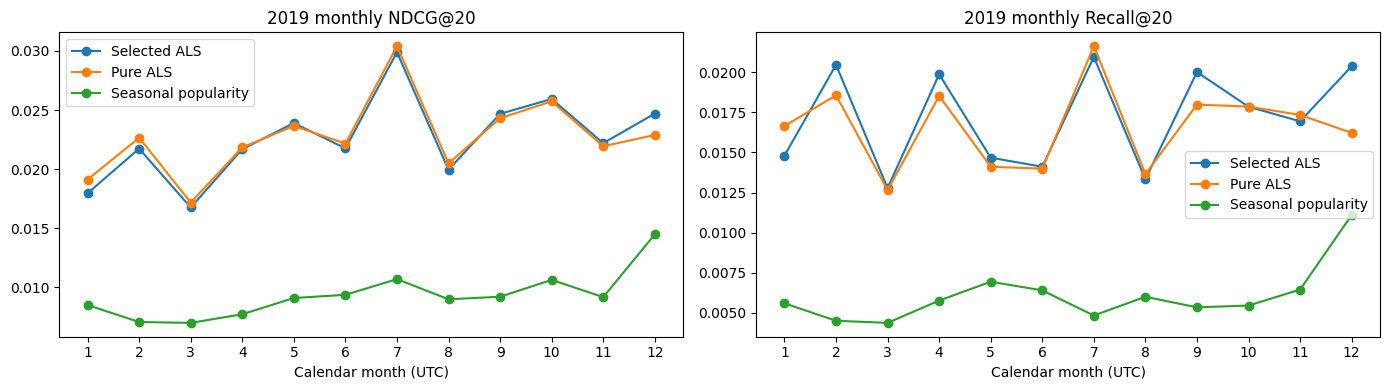

Results average only active, eligible user/month queries; inspect coverage above.


In [12]:
test_completion_path = REPORT_DIR / "test_evaluation_complete.json"
if test_completion_path.exists():
    completed = json.loads(test_completion_path.read_text())
    if completed["bundle_id"] != bundle_id:
        raise ValueError("Test results belong to a different bundle. Use a new RUN_NAME.")
    print("Reusing saved test results; test evaluation was already completed.")
    test_results = pd.read_csv(REPORT_DIR / "test_comparison.csv")
    test_coverage = pd.read_csv(REPORT_DIR / "test_target_coverage.csv")
else:
    test_queries, test_coverage = target_queries("test")
    comparison = []
    for label, model, mode, weight in (
        ("test_selected", selected_model, "als", selected_weight),
        ("test_pure_als", selected_model, "als", 0.0),
        ("test_popularity", None, "popularity", 0.0),
        ("test_seasonal_popularity", None, "seasonal_popularity", 0.0),
    ):
        result, _ = evaluate(
            model, test_queries, label, mode=mode,
            seasonal_weight=weight, save_details=True,
        )
        comparison.append(result)
    test_results = pd.DataFrame(comparison)
    test_results.to_csv(REPORT_DIR / "test_comparison.csv", index=False)
    test_completion_path.write_text(json.dumps({
        "bundle_id": bundle_id,
        "test_year": TEST_YEAR,
        "completed_at_utc": datetime.now(timezone.utc).isoformat(),
        "protocol": CONFIG["protocol"],
        "selection": selection,
    }, indent=2))

display(test_coverage)
display(test_results)
monthly_selected = pd.read_csv(REPORT_DIR / "test_selected_monthly_metrics.csv").set_index("month")
monthly_pure = pd.read_csv(REPORT_DIR / "test_pure_als_monthly_metrics.csv").set_index("month")
monthly_seasonal_baseline = pd.read_csv(
    REPORT_DIR / "test_seasonal_popularity_monthly_metrics.csv"
).set_index("month")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, monthly in (
    ("Selected ALS", monthly_selected),
    ("Pure ALS", monthly_pure),
    ("Seasonal popularity", monthly_seasonal_baseline),
):
    axes[0].plot(monthly.index, monthly[f"ndcg@{K}"], marker="o", label=name)
    axes[1].plot(monthly.index, monthly[f"recall@{K}"], marker="o", label=name)
for ax, metric in zip(axes, (f"NDCG@{K}", f"Recall@{K}")):
    ax.set_title(f"{TEST_YEAR} monthly {metric}")
    ax.set_xlabel("Calendar month (UTC)")
    ax.set_xticks(range(1, 13))
    ax.legend()
fig.tight_layout()
fig.savefig(REPORT_DIR / "test_monthly_ranking.png", dpi=150)
plt.show()
print("Results average only active, eligible user/month queries; inspect coverage above.")


## 12. Inference pipeline: load a bundle and recommend songs

For inference in a fresh runtime, run dependency installation, then just this class-definition cell and the following example cell with the saved bundle path. Training, DuckDB preprocessing, and evaluation functions are unnecessary.

Known training users receive personalized latent-factor scores plus the validation-selected month feature, excluding their retained training songs. Unknown users receive an explicitly labeled train-only seasonal-popularity fallback. Cold-user fallback quality is not included in the warm-only evaluation above. Songs outside the training catalog have no factors and cannot be recommended by this model.

The request date must be at or after the training cutoff. This check prevents requesting historical recommendations from a model trained on later events. Histories and factors remain frozen at training time. Scores are ranking scores, not probabilities. Output uses original song IDs; human-readable names require a separate item metadata table and are not provided by the interaction file.


In [13]:
# This cell is self-contained after installing the dependencies.
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from implicit.cpu.als import AlternatingLeastSquares
from scipy import sparse

class SongRecommender:
    def __init__(self, bundle_dir, metadata_csv=None):
        self.bundle_dir = Path(bundle_dir)
        manifest = json.loads((self.bundle_dir / "BUNDLE_MANIFEST.json").read_text())
        expected_bundle_id = hashlib.sha256(
            json.dumps(manifest["files"], sort_keys=True).encode("utf-8")
        ).hexdigest()
        if expected_bundle_id != manifest["bundle_id"]:
            raise ValueError("Bundle manifest identity mismatch.")
        for name, expected in manifest["files"].items():
            # Manifest entries are flat bundle filenames.
            if Path(name).name != name:
                raise ValueError("Invalid bundle filename.")
            path = self.bundle_dir / name
            digest = hashlib.sha256()
            with path.open("rb") as handle:
                for block in iter(lambda: handle.read(8 * 1024 * 1024), b""):
                    digest.update(block)
            if path.stat().st_size != expected["bytes"] or digest.hexdigest() != expected["sha256"]:
                raise ValueError(f"Corrupt or mismatched bundle file: {name}")

        self.config = json.loads((self.bundle_dir / "config.json").read_text())
        self.selection = json.loads((self.bundle_dir / "selection.json").read_text())
        self.cutoff = pd.Timestamp(self.selection["training_cutoff_exclusive"])
        self.weight = float(self.selection["seasonal_weight"])
        self.model = AlternatingLeastSquares.load(self.bundle_dir / "model.npz")
        self.counts = sparse.load_npz(self.bundle_dir / "train_counts.npz").tocsr()
        users = pd.read_parquet(self.bundle_dir / "users.parquet").sort_values("user_index")
        items = pd.read_parquet(self.bundle_dir / "items.parquet").sort_values("item_index")
        self.user_ids = users["user_id"].astype(str).to_numpy()
        self.item_ids = items["item_id"].astype(str).to_numpy()
        assert np.array_equal(users["user_index"].to_numpy(), np.arange(len(users)))
        assert np.array_equal(items["item_index"].to_numpy(), np.arange(len(items)))
        self.user_lookup = {value: index for index, value in enumerate(self.user_ids)}
        self.item_lookup = {value: index for index, value in enumerate(self.item_ids)}
        with np.load(self.bundle_dir / "priors.npz", allow_pickle=False) as priors:
            self.seasonal_features = priors["seasonal_features"].copy()
            self.seasonal_popularity = priors["seasonal_popularity"].copy()
        assert self.counts.shape == (len(self.user_ids), len(self.item_ids))
        assert self.model.user_factors.shape[0] == len(self.user_ids)
        assert self.model.item_factors.shape[0] == len(self.item_ids)
        assert self.seasonal_features.shape == (12, len(self.item_ids))
        assert self.seasonal_popularity.shape == (12, len(self.item_ids))
        self.metadata = None
        if metadata_csv is not None:
            metadata = pd.read_csv(metadata_csv, dtype="string")
            if "item_id" not in metadata.columns or metadata["item_id"].duplicated().any():
                raise ValueError("Metadata needs a unique item_id column.")
            allowed = ["item_id"] + [c for c in ("title", "artist") if c in metadata.columns]
            self.metadata = metadata[allowed]

    def recommend(self, user_id, as_of, k=20):
        if not isinstance(k, (int, np.integer)) or k < 1:
            raise ValueError("k must be a positive integer.")
        when = pd.to_datetime(as_of, utc=True, errors="raise")
        if pd.isna(when) or when < self.cutoff:
            raise ValueError(f"as_of must be at or after training cutoff {self.cutoff}.")
        month = int(when.month)
        user = self.user_lookup.get(str(user_id))
        if user is None:
            scores = self.seasonal_popularity[month - 1].copy()
            strategy = "cold_user_seasonal_popularity"
        else:
            scores = self.model.user_factors[user] @ self.model.item_factors.T
            if self.weight:
                scores = (scores - scores.mean()) / max(float(scores.std()), 1e-6)
                scores += self.weight * self.seasonal_features[month - 1]
            start, end = self.counts.indptr[user:user + 2]
            scores[self.counts.indices[start:end]] = -np.inf
            strategy = "personalized_als"
        available = np.flatnonzero(np.isfinite(scores))
        # Exact catalog ranking with deterministic index tie-breaking.
        ordered = available[np.lexsort((available, -scores[available]))[:int(k)]]
        result = pd.DataFrame({
            "rank": np.arange(1, len(ordered) + 1),
            "item_id": self.item_ids[ordered],
            "score": scores[ordered],
            "strategy": strategy,
            "as_of_utc": when.isoformat(),
        })
        if self.metadata is not None:
            result = result.merge(self.metadata, on="item_id", how="left", validate="many_to_one")
        return result

    def similar_songs(self, item_id, k=10):
        item = self.item_lookup.get(str(item_id))
        if item is None:
            raise KeyError("Song is outside the retained training catalog.")
        if not isinstance(k, (int, np.integer)) or k < 1:
            raise ValueError("k must be a positive integer.")
        factors = self.model.item_factors
        norms = np.linalg.norm(factors, axis=1)
        scores = (factors @ factors[item]) / np.maximum(norms * norms[item], 1e-12)
        scores[item] = -np.inf
        available = np.flatnonzero(np.isfinite(scores))
        ordered = available[np.lexsort((available, -scores[available]))[:int(k)]]
        result = pd.DataFrame({
            "rank": np.arange(1, len(ordered) + 1),
            "item_id": self.item_ids[ordered],
            "cosine_similarity": scores[ordered],
        })
        if self.metadata is not None:
            result = result.merge(self.metadata, on="item_id", how="left", validate="many_to_one")
        return result


In [14]:
# Change this path when loading a copied or unzipped bundle in a fresh runtime.
SAVED_BUNDLE = "/content/music4all_onion/runs/yearly_2014_2017_val2018_test2019_users10pct_v1/bundle"
# When running this notebook end-to-end, prefer the configured path.
if "BUNDLE_DIR" in globals():
    SAVED_BUNDLE = str(BUNDLE_DIR)

recommender = SongRecommender(SAVED_BUNDLE)
example_user_id = recommender.user_ids[0]  # replace with an original dataset user ID
example_date = f"{recommender.config['test_year']}-01-01"

display(recommender.recommend(example_user_id, as_of=example_date, k=20))
display(recommender.recommend("new_user_example", as_of=example_date, k=10))
display(recommender.similar_songs(recommender.item_ids[0], k=10))

# Optional readable names:
# recommender = SongRecommender(SAVED_BUNDLE, metadata_csv="/content/song_metadata.csv")
# song_metadata.csv columns: item_id,title,artist (item_id must match original song IDs).


,rank,item_id,score,strategy,as_of_utc
0,1,USLM5pkhFI0MwCPx,6.027349,personalized_als,2019-01-01T00:00:00+00:00
1,2,aL3vsWD4HHtypGPc,5.956641,personalized_als,2019-01-01T00:00:00+00:00
2,3,8xZbP00VbufGKeYj,5.509314,personalized_als,2019-01-01T00:00:00+00:00
3,4,vqFYS6LzsyiT21RG,5.436885,personalized_als,2019-01-01T00:00:00+00:00
4,5,tpvm0LJPoZ5D2WCJ,5.207301,personalized_als,2019-01-01T00:00:00+00:00
5,6,qES5o94VP8t2XZTT,5.162650,personalized_als,2019-01-01T00:00:00+00:00
6,7,0LwxuBXTAocDysDB,5.110942,personalized_als,2019-01-01T00:00:00+00:00
7,8,qtv8RQXJHdlOH9dW,5.097642,personalized_als,2019-01-01T00:00:00+00:00
8,9,gRGd4QUxoeyTNMan,4.975565,personalized_als,2019-01-01T00:00:00+00:00
9,10,xsT4uiJbiPwaZL74,4.959281,personalized_als,2019-01-01T00:00:00+00:00


,rank,item_id,score,strategy,as_of_utc
0,1,yfm7RER1PWTqgjIp,0.001189,cold_user_seasonal_popularity,2019-01-01T00:00:00+00:00
1,2,DIenz1hGgjltkjQF,0.000827,cold_user_seasonal_popularity,2019-01-01T00:00:00+00:00
2,3,0ng9VQtWuSjd0arq,0.000820,cold_user_seasonal_popularity,2019-01-01T00:00:00+00:00
3,4,CZgE6qZWTgosz0DS,0.000808,cold_user_seasonal_popularity,2019-01-01T00:00:00+00:00
4,5,wQ4RdMXUKj1ry4p6,0.000707,cold_user_seasonal_popularity,2019-01-01T00:00:00+00:00
5,6,EmPJO7fTwQlTDjGG,0.000688,cold_user_seasonal_popularity,2019-01-01T00:00:00+00:00
6,7,zp4zYVjiH2Tm3gTM,0.000681,cold_user_seasonal_popularity,2019-01-01T00:00:00+00:00
7,8,m7JmmCLKTtXkuFs3,0.000644,cold_user_seasonal_popularity,2019-01-01T00:00:00+00:00
8,9,8Ru0zKi4RmKM3UrW,0.000613,cold_user_seasonal_popularity,2019-01-01T00:00:00+00:00
9,10,lZDk11KaRskQqhWf,0.000611,cold_user_seasonal_popularity,2019-01-01T00:00:00+00:00


,rank,item_id,cosine_similarity
0,1,2ht4hpLaCk1ijw7d,0.677810
1,2,ZKrXPhUBUvwDiv1V,0.634784
2,3,lZLoqJi4I1n6M8rh,0.630420
3,4,1oWlFugpgpvUjOfV,0.600692
4,5,d8EZO9zZiQXWxeSH,0.598375
5,6,WUcpacYE4BAozlYv,0.552612
6,7,dR2YlcLAsPyEHKDB,0.467629
7,8,ZE9xMgCc4CJ6nRa0,0.466310
8,9,PaJbBF61dVRO9yNe,0.465857
9,10,OW0o6jmWSTOovFKD,0.465079


## 13. Optional export

The bundle can be reloaded for inference without downloading the interaction data again. It includes training IDs and histories and can be large. Reports, raw data, DuckDB state, and split manifests are outside the bundle. Save any of those separately if needed before Colab disconnects.

Set an export toggle below only when you want to copy or download the generated bundle. For Drive export, Colab asks you to authorize mounting Google Drive at runtime.


In [15]:
EXPORT_TO_DRIVE = False
DOWNLOAD_BUNDLE = False
DRIVE_DESTINATION = "/content/drive/MyDrive/music4all_onion_models"

if EXPORT_TO_DRIVE or DOWNLOAD_BUNDLE:
    import shutil
    from pathlib import Path
    saved_bundle = Path(SAVED_BUNDLE)
    archive_path = Path(shutil.make_archive(
        str(saved_bundle.parent / f"{saved_bundle.parent.name}_bundle"),
        "zip", root_dir=saved_bundle.parent, base_dir=saved_bundle.name,
    ))
    print("Bundle archive:", archive_path)
    if EXPORT_TO_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        destination = Path(DRIVE_DESTINATION)
        destination.mkdir(parents=True, exist_ok=True)
        shutil.copy2(archive_path, destination / archive_path.name)
        print("Copied to:", destination / archive_path.name)
    if DOWNLOAD_BUNDLE:
        from google.colab import files
        files.download(str(archive_path))
else:
    print("Export disabled. The inference bundle remains on Colab's local disk.")


Export disabled. The inference bundle remains on Colab's local disk.


## Output map and interpretation

Under the configured run directory:

- manifests/split=train, split=val, split=test: globally deduplicated event-level Parquet split manifests with user_id, item_id, timestamp, year, month, and a split partition label. Read with hive_partitioning=true to recover that label.
- SPLIT_METADATA.json, source.json, config.json, environment.json: boundaries, file inventory, sampling, cleaning counts, provenance, and settings.
- model_data/: training-only numeric ID maps, play-count CSR, pair table, priors, and saved evaluation user indices.
- reports/: split/calendar summaries, coverage tables, validation search and baselines, per-query and per-month metrics, training timing, and charts.
- bundle/: locked ALS factors and everything required by SongRecommender; BUNDLE_MANIFEST.json checks that its files belong together.

The validation-selected model need not beat popularity or pure ALS. Report those comparisons, the sampled cohort size, future-label coverage, and each month's query count. Seasonal gains can be confounded with trends and sparse user activity; a single three-way calendar split does not establish a general seasonal effect. For a stronger study, repeat the protocol at earlier rolling year cutoffs, selecting settings within each fold, and reserve the final future year for one final test. Avoid repeatedly choosing models from the final test results.

**Dataset citation:** Moscati et al. (2022), [Music4All-Onion — A Large-Scale Multi-faceted Content-Centric Music Recommendation Dataset](https://doi.org/10.1145/3511808.3557656). Dataset files: [Zenodo v2](https://zenodo.org/records/15394646). ALS implementation: [implicit 0.7.2 documentation](https://benfred.github.io/implicit/api/models/cpu/als.html). The official interaction schema is also used by the [RecSysDatasets conversion implementation](https://github.com/RUCAIBox/RecSysDatasets/blob/master/conversion_tools/src/extended_dataset.py).
